In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, max_error
from sklearn.ensemble import RandomForestRegressor


In [3]:
daily_df = pd.read_csv('C:\\Users\\amand\\OneDrive\\Documents\\Electricity Bill and Consumption Analyzer\\processed data\\daily_household_power_consumption.csv', parse_dates=['datetime'], index_col='datetime')

# Verify it loaded correctly
print(daily_df.head())

            daily_consumption_kwh  valid_readings_count  is_complete
datetime                                                            
2006-12-16              20.152933                   396        False
2006-12-17              56.507667                  1440         True
2006-12-18              36.730433                  1440         True
2006-12-19              27.769900                  1440         True
2006-12-20              37.095800                  1440         True


In [4]:
monthly_df = pd.read_csv('C:\\Users\\amand\\OneDrive\\Documents\\Electricity Bill and Consumption Analyzer\\processed data\\monthly_energy_costs.csv', parse_dates=['datetime'], index_col='datetime')


# Verify it loaded correctly
print(monthly_df.head())

            monthly_consumption_kwh  monthly_cost  recorded_days  \
datetime                                                           
2006-12-31                   696.98        348.49             16   
2007-01-31                  1150.22        575.11             31   
2007-02-28                   941.52        470.76             28   
2007-03-31                   981.05        490.52             31   
2007-04-30                   640.03        320.02             30   

            complete_days  days_in_month  is_partial_month  
datetime                                                    
2006-12-31             15             31              True  
2007-01-31             31             31             False  
2007-02-28             28             28             False  
2007-03-31             31             31             False  
2007-04-30             30             30             False  


In [5]:
TARIFF_PER_KWH = 0.50 #to set the tariff per kWh

In [6]:
daily_df['daily_cost'] = daily_df['daily_consumption_kwh'] * TARIFF_PER_KWH #calculate the daily cost based on the daily consumption and the tariff per kWh

In [7]:
average_daily_cost = daily_df['daily_cost'].mean()
average_daily_consumption = daily_df['daily_consumption_kwh'].mean() #average daily cost and consumption for the entire dataset
print(f"Average Daily Cost: ${average_daily_cost:.2f}")
print(f"Average Daily Consumption: {average_daily_consumption:.2f} kWh")

Average Daily Cost: $13.06
Average Daily Consumption: 26.12 kWh


In [8]:
highest_day_date = daily_df['daily_consumption_kwh'].idxmax()
lowest_day_date = daily_df['daily_consumption_kwh'].idxmin() #identified the dates with the highest and lowest daily consumption

In [9]:
highest_day = daily_df.loc[highest_day_date]
lowest_day = daily_df.loc[lowest_day_date] #extracted the rows corresponding to the highest and lowest daily consumption

In [10]:
print("Highest Consumption Day:")
print(f"Date: {highest_day_date.strftime('%Y-%m-%d')}")
print(f"Consumption: {highest_day['daily_consumption_kwh']:.2f} kWh")
print(f"Complete Day?: {highest_day['is_complete']}\n")

print("Lowest Consumption Day:")
print(f"Date: {lowest_day_date.strftime('%Y-%m-%d')}")
print(f"Consumption: {lowest_day['daily_consumption_kwh']:.2f} kWh")
print(f"Complete Day?: {lowest_day['is_complete']}")

Highest Consumption Day:
Date: 2006-12-23
Consumption: 79.56 kWh
Complete Day?: True

Lowest Consumption Day:
Date: 2008-08-25
Consumption: 4.17 kWh
Complete Day?: True


In [11]:
# Created a 'Day_Type' column (Weekday vs Weekend)
# dayofweek: 0-4 are Monday-Friday (Weekdays), 5-6 are Saturday-Sunday (Weekends)

daily_df['day_of_week'] = daily_df.index.dayofweek
daily_df['Day_Type'] = daily_df['day_of_week'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')
#i want to compare weekday use and weekend use and see if there is a significant difference in consumption. I will use a boxplot to visualize the distribution of daily consumption for weekdays and weekends.

print(daily_df.groupby('Day_Type')['daily_consumption_kwh'].mean()) #using groupby to calculate the average daily consumption for weekdays and weekends, which would be used to see if there's a significant diference in use on weekdays and weekends

Day_Type
Weekday    24.812021
Weekend    29.385474
Name: daily_consumption_kwh, dtype: float64


C:\Users\amand\AppData\Local\Temp\ipykernel_22300\1804541279.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Day_Type', y='daily_consumption_kwh', data=daily_df, palette='Set2')


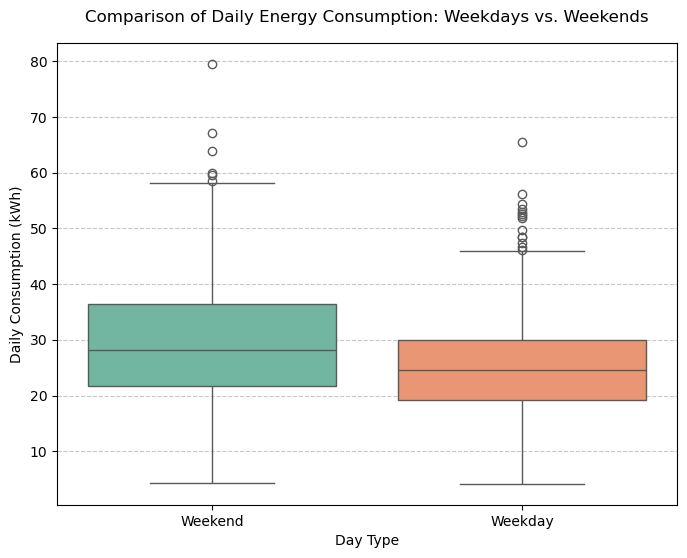

In [12]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Day_Type', y='daily_consumption_kwh', data=daily_df, palette='Set2')

plt.title('Comparison of Daily Energy Consumption: Weekdays vs. Weekends', fontsize=12, pad=15)
plt.xlabel('Day Type', fontsize=10)
plt.ylabel('Daily Consumption (kWh)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

As shown above there isnt really a significant difference between electricity consumption on weekdays and weekends. Though the increase on weekends can be explained on the assumption of the people tend to sleep later on weekends. And they arent going to work, especially those doing a 9-5, so they can spend the day, watching television, baking, laundry, gaming and other activities that take up electricity.

In [13]:
#Calculated a rolling threshold (e.g., 7-day average + 2 standard deviations)
daily_df['rolling_mean'] = daily_df['daily_consumption_kwh'].rolling(window=7).mean()
daily_df['rolling_std'] = daily_df['daily_consumption_kwh'].rolling(window=7).std()

# Defined the alert rule: 2 standard deviations above the recent average
daily_df['high_consumption_alert'] = daily_df['daily_consumption_kwh'] > (daily_df['rolling_mean'] + 2 * daily_df['rolling_std'])

# Viewed days that triggered the alert
alert_days = daily_df[daily_df['high_consumption_alert']]
print(f"Total high consumption alerts triggered: {len(alert_days)}")
print(alert_days[['daily_consumption_kwh']])

Total high consumption alerts triggered: 21
            daily_consumption_kwh
datetime                         
2007-02-18              63.829367
2007-03-03              13.652033
2007-03-04              34.845000
2007-05-01              27.730967
2007-06-16              33.629367
2007-07-07              22.636767
2007-09-16              27.537067
2007-09-25              29.405700
2008-01-12              47.856800
2008-08-31              25.026533
2008-11-05              52.248833
2008-11-23              56.778067
2009-08-09              16.637233
2009-09-12              34.405967
2009-10-17              45.701333
2010-02-21              45.671900
2010-03-08              42.618300
2010-05-02              36.465167
2010-05-29              34.163467
2010-08-15              17.599767
2010-09-29              28.073767


The high consumption alert rule: Trigger an alert if today's consumption is more than 2 standard deviations above the average of the previous 7 days.
Why? It watches for sudden, unusual spikes relative to my recent habits, automatically adjusting for seasons.

In [14]:
TARIFF_PER_KWH = 0.50
if 'daily_cost' not in daily_df.columns:
    daily_df['daily_cost'] = daily_df['daily_consumption_kwh'] * TARIFF_PER_KWH

In [15]:
sns.set_theme(style="whitegrid")


**Daily Consumption Over Time**


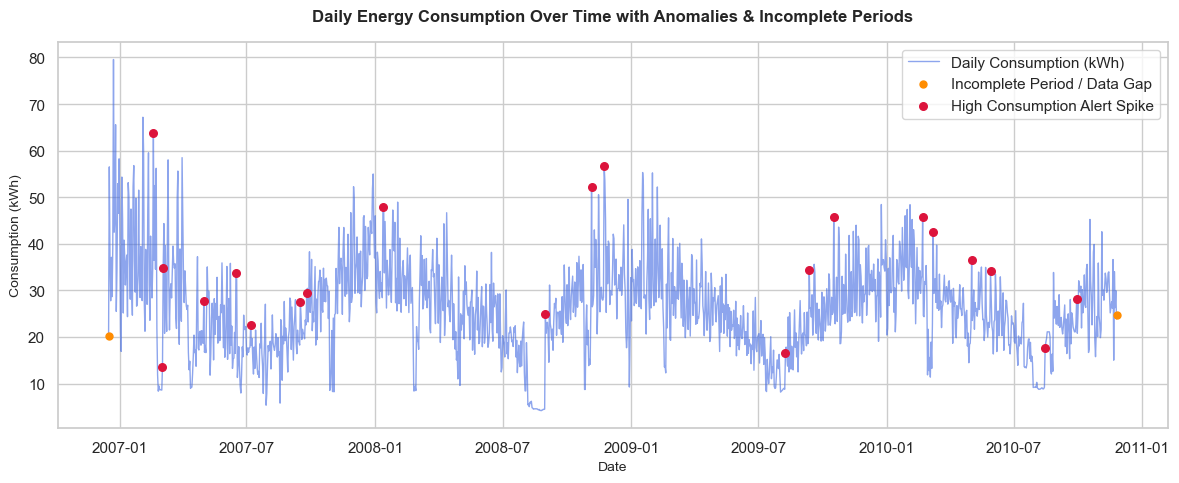

In [16]:

fig, ax = plt.subplots(figsize=(12, 5))

# Plot baseline daily consumption line
ax.plot(daily_df.index, daily_df['daily_consumption_kwh'], label='Daily Consumption (kWh)', color='royalblue', alpha=0.6, linewidth=1)

# Highlight incomplete days (orange markers)
incomplete_days = daily_df[daily_df['is_complete'] == False]
ax.scatter(incomplete_days.index, incomplete_days['daily_consumption_kwh'], color='darkorange', label='Incomplete Period / Data Gap', zorder=5, s=25)

# Highlight high-consumption spikes (red markers)
high_days = daily_df[daily_df['high_consumption_alert'] == True]
ax.scatter(high_days.index, high_days['daily_consumption_kwh'], color='crimson', label='High Consumption Alert Spike', zorder=6, s=30)

ax.set_title('Daily Energy Consumption Over Time with Anomalies & Incomplete Periods', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=10)
ax.set_ylabel('Consumption (kWh)', fontsize=10)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

**Daily Energy Costs Over Time**

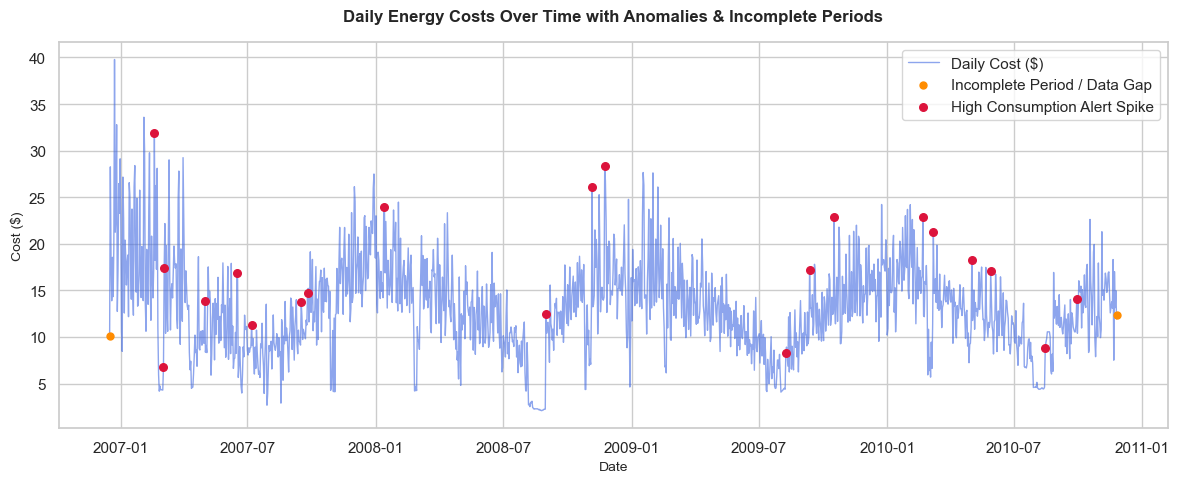

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

# Plot baseline daily cost line (using 'daily_cost' instead of kWh)
ax.plot(daily_df.index, daily_df['daily_cost'], label='Daily Cost ($)', color='royalblue', alpha=0.6, linewidth=1)

# Highlight incomplete days (orange markers)
incomplete_days = daily_df[daily_df['is_complete'] == False]
ax.scatter(incomplete_days.index, incomplete_days['daily_cost'], color='darkorange', label='Incomplete Period / Data Gap', zorder=5, s=25)

# Highlight high-consumption spikes (red markers)
high_days = daily_df[daily_df['high_consumption_alert'] == True]
ax.scatter(high_days.index, high_days['daily_cost'], color='crimson', label='High Consumption Alert Spike', zorder=6, s=30)

ax.set_title('Daily Energy Costs Over Time with Anomalies & Incomplete Periods', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=10)
ax.set_ylabel('Cost ($)', fontsize=10)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

**Monthly consumption and costs**

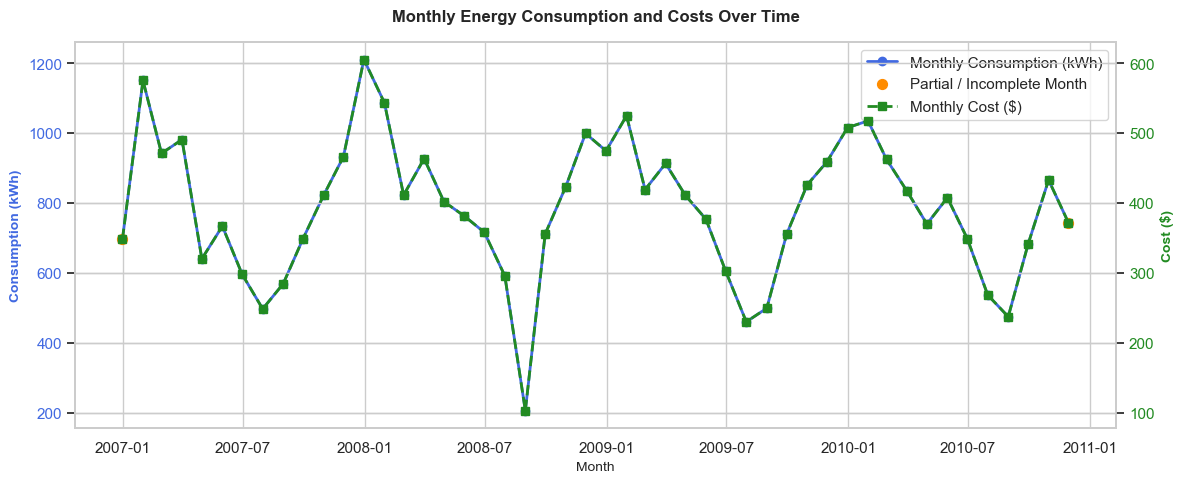

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))

# Plot monthly energy consumption (left y-axis)
ax.plot(monthly_df.index, monthly_df['monthly_consumption_kwh'], label='Monthly Consumption (kWh)', color='royalblue', marker='o', linewidth=2)
ax.set_ylabel('Consumption (kWh)', color='royalblue', fontsize=10, fontweight='bold')
ax.tick_params(axis='y', labelcolor='royalblue')

# Create a secondary y-axis for monthly costs (right y-axis)
ax2 = ax.twinx()
ax2.plot(monthly_df.index, monthly_df['monthly_cost'], label='Monthly Cost ($)', color='forestgreen', marker='s', linestyle='--', linewidth=2)
ax2.set_ylabel('Cost ($)', color='forestgreen', fontsize=10, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='forestgreen')

# Highlight partial/incomplete months if the column exists
if 'is_partial_month' in monthly_df.columns:
    partial_months = monthly_df[monthly_df['is_partial_month'] == True]
    if not partial_months.empty:
        ax.scatter(partial_months.index, partial_months['monthly_consumption_kwh'], color='darkorange', label='Partial / Incomplete Month', zorder=5, s=50)

# Combine legends from both axes
lines_1, labels_1 = ax.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', frameon=True)

ax.set_title('Monthly Energy Consumption and Costs Over Time', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=10)
plt.tight_layout()
plt.show()

**Modelling**

Building a simple forecasting Baseline

In [19]:
#Calculated the recent average daily consumption (using the last 30 days)
recent_window_days = 30
recent_avg_daily_kwh = daily_df['daily_consumption_kwh'].tail(recent_window_days).mean()
print(recent_avg_daily_kwh)

28.27514777777778


In [20]:
print(monthly_df.tail())

            monthly_consumption_kwh  monthly_cost  recorded_days  \
datetime                                                           
2010-07-31                   536.47        268.24             31   
2010-08-31                   474.60        237.30             31   
2010-09-30                   682.02        341.01             30   
2010-10-31                   865.56        432.78             31   
2010-11-30                   743.31        371.65             26   

            complete_days  days_in_month  is_partial_month  
datetime                                                    
2010-07-31             31             31             False  
2010-08-31             31             31             False  
2010-09-30             30             30             False  
2010-10-31             31             31             False  
2010-11-30             25             30              True  


In [21]:
#Automatically determine the year and month for the forecast (the month after the dataset ends)
last_date = daily_df.index.max()
if last_date.month == 12:
    forecast_year = last_date.year + 1
    forecast_month = 1
else:
    forecast_year = last_date.year
    forecast_month = last_date.month + 1

In [22]:
#Get the exact number of days in that upcoming month (accounts for leap years, 28 & 30 & 31 days)
forecast_days_count = pd.Period(f"{forecast_year}-{forecast_month:02d}", freq='M').days_in_month
print(forecast_days_count)

31


In [23]:
forecasted_consumption_kwh = recent_avg_daily_kwh * forecast_days_count #Multiplies daily average by the days in the month to get total consumption
print(forecasted_consumption_kwh)

876.5295811111112


In [24]:
forecasted_cost = forecasted_consumption_kwh * TARIFF_PER_KWH

In [25]:
#Displays the results clearly
print(f"==================================================")
print(f" SIMPLE BASELINE FORECAST FOR {forecast_year}-{forecast_month:02d}")
print(f"==================================================")
print(f"Based on the last {recent_window_days}-day average: {recent_avg_daily_kwh:.2f} kWh/day")
print(f"Days in target month: {forecast_days_count} days")
print(f"--------------------------------------------------")
print(f"Forecasted Total Consumption : {forecasted_consumption_kwh:,.2f} kWh")
print(f"Forecasted Total Cost        : ${forecasted_cost:,.2f}")
print(f"==================================================")
print("*Note: This estimate assumes that the tariff remains unchanged at")
print(f" ${TARIFF_PER_KWH:.2f} per kWh throughout the forecast period.")

 SIMPLE BASELINE FORECAST FOR 2010-12
Based on the last 30-day average: 28.28 kWh/day
Days in target month: 31 days
--------------------------------------------------
Forecasted Total Consumption : 876.53 kWh
Forecasted Total Cost        : $438.26
*Note: This estimate assumes that the tariff remains unchanged at
 $0.50 per kWh throughout the forecast period.


In [26]:
evaluation_results = []

# Looping through each month in the monthly dataframe (skipping the first month since we need prior daily data)
monthly_periods = monthly_df.index[1:] 

for target_month in monthly_periods:
    # Finds the start and end of this target month
    month_start = target_month.replace(day=1)
    
    # Gets days in this target month
    days_in_month = target_month.days_in_month
    
    # Gets actual consumption and cost for this month
    actual_kwh = monthly_df.loc[target_month, 'monthly_consumption_kwh']
    actual_cost = monthly_df.loc[target_month, 'monthly_cost']
    
    # Gets the 30 days of daily data immediately preceding this month to use as our baseline window
    prior_daily_data = daily_df[daily_df.index < month_start].tail(30)
    
    if len(prior_daily_data) < 30:
        continue # Skips if we don't have a full 30 days of history
        
    # Calculates baseline forecast for this month
    predicted_daily_avg_kwh = prior_daily_data['daily_consumption_kwh'].mean()
    predicted_kwh = predicted_daily_avg_kwh * days_in_month
    predicted_cost = predicted_kwh * TARIFF_PER_KWH
    
    # Calculates errors
    absolute_error_cost = abs(predicted_cost - actual_cost)
    percentage_error = (absolute_error_cost / actual_cost) * 100
    
    evaluation_results.append({
        'Month': target_month.strftime('%Y-%m'),
        'Actual_Cost': actual_cost,
        'Predicted_Cost': predicted_cost,
        'Absolute_Error_$': absolute_error_cost,
        'Percentage_Error_%': percentage_error
    })

# Converts results to a DataFrame
eval_df = pd.DataFrame(evaluation_results)

# Calculates final evaluation metrics (MAE and MAPE)
mean_absolute_error = eval_df['Absolute_Error_$'].mean()
mean_absolute_percentage_error = eval_df['Percentage_Error_%'].mean()

print("==================================================")
print(" BASELINE FORECAST EVALUATION RESULTS")
print("==================================================")
print(eval_df.to_string(index=False))
print("--------------------------------------------------")
print(f"Mean Absolute Error (MAE): ${mean_absolute_error:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mean_absolute_percentage_error:.2f}%")
print("==================================================")

 BASELINE FORECAST EVALUATION RESULTS
  Month  Actual_Cost  Predicted_Cost  Absolute_Error_$  Percentage_Error_%
2007-02       470.76      515.390073         44.630073            9.480430
2007-03       490.52      521.513448         30.993448            6.318488
2007-04       320.02      486.210250        166.190250           51.931207
2007-05       366.74      330.684268         36.055732            9.831415
2007-06       297.72      352.875117         55.155117           18.525835
2007-07       248.40      307.642140         59.242140           23.849493
2007-08       284.39      247.841676         36.548324           12.851480
2007-09       348.97      275.309167         73.660833           21.108070
2007-10       410.66      360.598389         50.061611           12.190525
2007-11       466.01      396.323433         69.686567           14.953878
2007-12       605.04      481.538896        123.501104           20.412056
2008-01       543.09      598.217643         55.127643        

In [27]:
# Ensures the daily dataframe is sorted chronologically
daily_df = daily_df.sort_index()

# ----------------------------------------------------
# CALENDAR VARIABLES
# ----------------------------------------------------
# Extracts time-based patterns for the model
daily_df['day_of_week'] = daily_df.index.dayofweek          # 0=Monday, 6=Sunday
daily_df['month'] = daily_df.index.month                    # 1 through 12
daily_df['day_of_year'] = daily_df.index.dayofyear          # 1 through 365 (captures annual cycle)
daily_df['is_weekend'] = daily_df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

# ----------------------------------------------------
# LAG FEATURES (Historical Memory)
# ----------------------------------------------------
# shift(1) means "yesterday's consumption"
# shift(7) means "consumption exactly one week ago today"
daily_df['consumption_lag_1'] = daily_df['daily_consumption_kwh'].shift(1)
daily_df['consumption_lag_7'] = daily_df['daily_consumption_kwh'].shift(7)

# ----------------------------------------------------
# ROLLING AVERAGES (Recent Trends)
# ----------------------------------------------------
# CRITICAL: I use .shift(1) BEFORE calculating the rolling window. 
# This ensures the window looks ONLY at past days, strictly excluding today (preventing data leakage).
daily_df['rolling_mean_7'] = daily_df['daily_consumption_kwh'].shift(1).rolling(window=7).mean()
daily_df['rolling_mean_30'] = daily_df['daily_consumption_kwh'].shift(1).rolling(window=30).mean()

# ----------------------------------------------------
# 5. CLEAN UP NAs
# ----------------------------------------------------
# Because of the 30-day rolling window and lag features, the first 30 rows will contain NaNs.
# I dropped them to create a clean dataset ready for machine learning.
ml_df = daily_df.dropna().copy()

print(f"Original dataset rows: {len(daily_df)}")
print(f"Cleaned ML dataset rows: {len(ml_df)}")
print("\nPreview of engineered features:")
print(ml_df[['daily_consumption_kwh', 'is_weekend', 'consumption_lag_1', 'rolling_mean_7']].tail())

Original dataset rows: 1442
Cleaned ML dataset rows: 1412

Preview of engineered features:
            daily_consumption_kwh  is_weekend  consumption_lag_1  \
datetime                                                           
2010-11-22              34.025600           0          15.015167   
2010-11-23              26.292267           0          34.025600   
2010-11-24              29.937467           0          26.292267   
2010-11-25              23.852733           0          29.937467   
2010-11-26              24.801733           0          23.852733   

            rolling_mean_7  
datetime                    
2010-11-22       26.570548  
2010-11-23       27.270914  
2010-11-24       27.432314  
2010-11-25       27.942352  
2010-11-26       27.416190  


The Model being used is a regression model and tree based model. A linear regression model assumes relationships are straightforward (e.g., "every degree colder adds X kWh"). A tree-based model (like a Random Forest or XGBoost) breaks decisions into branches, which allows it to catch non-linear patterns and interactions (e.g., "if it's a winter weekend, usage patterns change differently than a winter weekday"). Comparing a linear model to a tree model shows whether the data has complex, twisting relationships or simple straight-line trends.

Splitting the Dataset for Training 

In [28]:
# Defines the target variable (what you want to predict) and your features
target_col = 'daily_consumption_kwh'

# Excludes the target column and the date index from the features (X)
feature_cols = [col for col in ml_df.columns if col != target_col]

X = ml_df[feature_cols]
y = ml_df[target_col]

# Chooses a chronological split point (reserve the last 20% of time for testing)
test_size_fraction = 0.20
split_index = int(len(ml_df) * (1 - test_size_fraction))

# Splits strictly by index order (no shuffling!)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Prints out date ranges to verify the split
print(f"Training Period: {X_train.index.min().strftime('%Y-%m-%d')} to {X_train.index.max().strftime('%Y-%m-%d')} ({len(X_train)} days)")
print(f"Testing Period:  {X_test.index.min().strftime('%Y-%m-%d')} to {X_test.index.max().strftime('%Y-%m-%d')} ({len(X_test)} days)")

Training Period: 2007-01-15 to 2010-02-16 (1129 days)
Testing Period:  2010-02-17 to 2010-11-26 (283 days)


Linear Regression Model

In [29]:
print(X_train.dtypes)

valid_readings_count        int64
is_complete                  bool
daily_cost                float64
day_of_week                 int32
Day_Type                   object
rolling_mean              float64
rolling_std               float64
high_consumption_alert       bool
month                       int32
day_of_year                 int32
is_weekend                  int64
consumption_lag_1         float64
consumption_lag_7         float64
rolling_mean_7            float64
rolling_mean_30           float64
dtype: object


i could do one hot encoding to change "Day_Type" into a float but i'm going to drop it because i dont need.

In [30]:
# Drops the text column and the target column from the feature set
drop_cols = ['Day_Type', 'daily_consumption_kwh']

feature_cols = [col for col in daily_df.columns if col not in drop_cols]

X = daily_df[feature_cols].dropna()
y = daily_df['daily_consumption_kwh'].loc[X.index] # Align y with cleaned X

# Re-runs the chronological split
test_size_fraction = 0.20
split_index = int(len(X) * (1 - test_size_fraction))

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Features cleaned! Ready to fit model.")

Features cleaned! Ready to fit model.


In [34]:
# Initializes the Linear Regression model
lr_model = LinearRegression()

# Trains (fit) the model on the training data
lr_model.fit(X_train, y_train)

# Predicts on the unseen test data
y_pred = lr_model.predict(X_test)

# Evaluates the model using regression metrics
mae = np.mean(np.abs(y_test - y_pred))
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("==================================================")
print(" LINEAR REGRESSION MODEL PERFORMANCE")
print("==================================================")
print(f"Mean Absolute Error (MAE):     ${mae:.2f} (per day)")
print(f"Root Mean Square Error (RMSE): ${rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print("==================================================")

 LINEAR REGRESSION MODEL PERFORMANCE
Mean Absolute Error (MAE):     $0.00 (per day)
Root Mean Square Error (RMSE): $0.00
Mean Absolute Percentage Error (MAPE): 0.00%


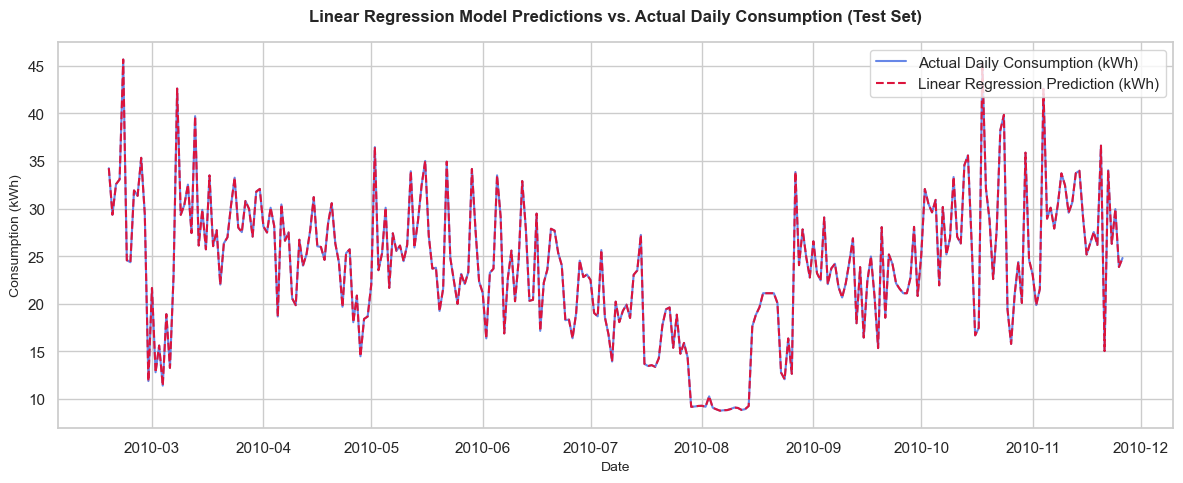

In [35]:
pred_series = pd.Series(y_pred, index=X_test.index)

#Sets up the plot format
fig, ax = plt.subplots(figsize=(12, 5))

# Plots actual consumption line
ax.plot(X_test.index, y_test, label='Actual Daily Consumption (kWh)', color='royalblue', linewidth=1.5, alpha=0.8)

# Plots model predicted consumption line
ax.plot(X_test.index, pred_series, label='Linear Regression Prediction (kWh)', color='crimson', linestyle='--', linewidth=1.5)

# Formats the chart
ax.set_title('Linear Regression Model Predictions vs. Actual Daily Consumption (Test Set)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=10)
ax.set_ylabel('Consumption (kWh)', fontsize=10)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

Tree Based Model

In [37]:
# Initializes the Random Forest Regressor
# (n_estimators=100 builds 100 decision trees; random_state ensures reproducible results)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Trains (fit) the model on the training data
rf_model.fit(X_train, y_train)

# Predicts on the unseen test data
y_pred_rf = rf_model.predict(X_test)

# Evaluates the model using regression metrics
mae_rf = np.mean(np.abs(y_test - y_pred_rf))
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mape_rf = np.mean(np.abs((y_test - y_pred_rf) / y_test)) * 100
r2_rf = r2_score(y_test, y_pred_rf)
max_err_rf = max_error(y_test, y_pred_rf)

print("==================================================")
print(" RANDOM FOREST MODEL EVALUATION")
print("==================================================")
print(f"Mean Absolute Error (MAE):     {mae_rf:.2f} kWh")
print(f"Root Mean Square Error (RMSE): {rmse_rf:.2f} kWh")
print(f"Mean Absolute Percentage Error (MAPE): {mape_rf:.2f}%")
print(f"R-squared (R² Score):          {r2_rf:.4f}")
print(f"Max Error (Worst Single Day):  {max_err_rf:.2f} kWh")
print("==================================================")

 RANDOM FOREST MODEL EVALUATION
Mean Absolute Error (MAE):     0.02 kWh
Root Mean Square Error (RMSE): 0.03 kWh
Mean Absolute Percentage Error (MAPE): 0.10%
R-squared (R² Score):          1.0000
Max Error (Worst Single Day):  0.19 kWh


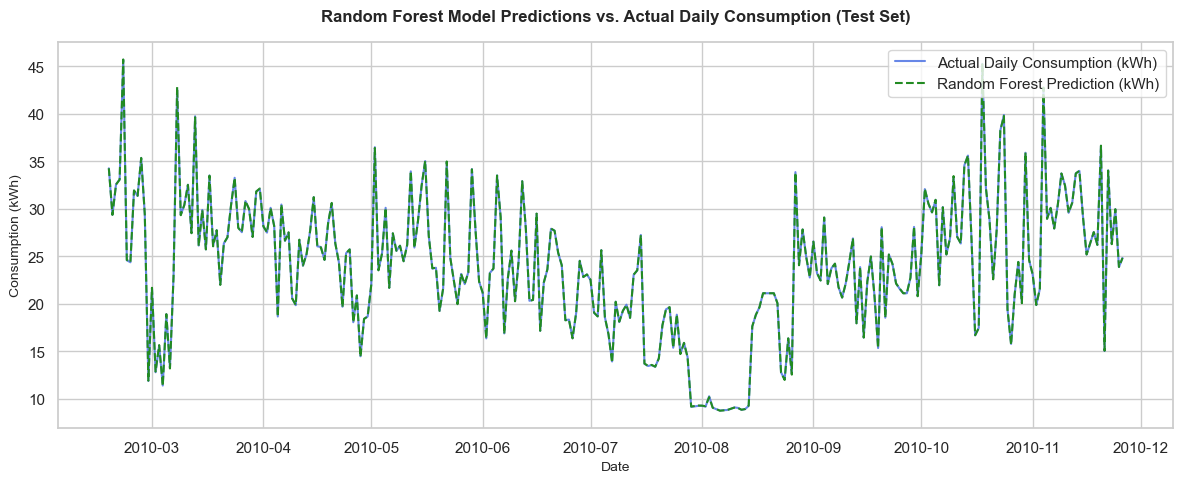

In [38]:
rf_pred_series = pd.Series(y_pred_rf, index=X_test.index)

#Sets up the plot format
fig, ax = plt.subplots(figsize=(12, 5))

# Plots actual consumption line
ax.plot(X_test.index, y_test, label='Actual Daily Consumption (kWh)', color='royalblue', linewidth=1.5, alpha=0.8)

# Plots Random Forest predicted consumption line
ax.plot(X_test.index, rf_pred_series, label='Random Forest Prediction (kWh)', color='forestgreen', linestyle='--', linewidth=1.5)

# Formats the chart
ax.set_title('Random Forest Model Predictions vs. Actual Daily Consumption (Test Set)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=10)
ax.set_ylabel('Consumption (kWh)', fontsize=10)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

In [39]:
# Combines test dates, actuals, and your ML predictions (using Random Forest here)
monthly_eval_df = pd.DataFrame({
    'actual_kwh': y_test,
    'predicted_kwh': y_pred_rf # Swap to y_pred if you want to test Linear Regression
}, index=X_test.index)

# Extracts Year-Month to group daily values into monthly totals
monthly_eval_df['year_month'] = monthly_eval_df.index.to_period('M')

# Sums daily consumption up to get monthly consumption totals
monthly_summary = monthly_eval_df.groupby('year_month').agg(
    actual_monthly_kwh=('actual_kwh', 'sum'),
    predicted_monthly_kwh=('predicted_kwh', 'sum'),
    days_in_test=('actual_kwh', 'count')
)

# Converts kWh into dollar costs using your tariff (e.g., $0.15 per kWh)
TARIFF_PER_KWH = 0.15
monthly_summary['Actual_Cost'] = monthly_summary['actual_monthly_kwh'] * TARIFF_PER_KWH
monthly_summary['Predicted_Cost'] = monthly_summary['predicted_monthly_kwh'] * TARIFF_PER_KWH

# Calculates monthly error metrics
monthly_summary['Absolute_Error_$'] = abs(monthly_summary['Predicted_Cost'] - monthly_summary['Actual_Cost'])
monthly_summary['Percentage_Error_%'] = (monthly_summary['Absolute_Error_$'] / monthly_summary['Actual_Cost']) * 100

# Finals summary averages
ml_monthly_mape = monthly_summary['Percentage_Error_%'].mean()
ml_monthly_mae = monthly_summary['Absolute_Error_$'].mean()

print("==================================================")
print(" MONTHLY AGGREGATED ML FORECAST VS. ACTUALS")
print("==================================================")
print(monthly_summary[['Actual_Cost', 'Predicted_Cost', 'Percentage_Error_%']].to_string())
print("--------------------------------------------------")
print(f"ML Model Monthly MAE:  ${ml_monthly_mae:.2f}")
print(f"ML Model Monthly MAPE: {ml_monthly_mape:.2f}%")
print(f"Baseline MAPE:         20.26%")
print("==================================================")

 MONTHLY AGGREGATED ML FORECAST VS. ACTUALS
            Actual_Cost  Predicted_Cost  Percentage_Error_%
year_month                                                 
2010-02       54.550015       54.559843            0.018017
2010-03      125.020735      125.026427            0.004552
2010-04      110.946550      110.948508            0.001765
2010-05      122.235205      122.209896            0.020705
2010-06      104.716305      104.716232            0.000070
2010-07       80.470895       80.486131            0.018934
2010-08       71.189765       71.157652            0.045109
2010-09      102.302315      102.302368            0.000052
2010-10      129.833635      129.820188            0.010357
2010-11      111.495970      111.528972            0.029600
--------------------------------------------------
ML Model Monthly MAE:  $0.01
ML Model Monthly MAPE: 0.01%
Baseline MAPE:         20.26%


In [40]:
#creates a clean dataframe for daily comparison
daily_eval_df = pd.DataFrame({
    'Actual_kWh': y_test,
    'Predicted_kWh': y_pred_rf # Uses your Random Forest predictions
}, index=X_test.index)

# Calculates daily absolute and percentage errors
daily_eval_df['Absolute_Error_kWh'] = abs(daily_eval_df['Predicted_kWh'] - daily_eval_df['Actual_kWh'])
daily_eval_df['Daily_MAPE_%'] = (daily_eval_df['Absolute_Error_kWh'] / daily_eval_df['Actual_kWh']) * 100

# Sorts by the highest percentage errors to see which days the model struggled with most
print("==================================================")
print(" TOP 10 HIGHEST DAILY ERROR DAYS")
print("==================================================")
print(daily_eval_df.sort_values(by='Daily_MAPE_%', ascending=False).head(10).to_string())

print("\n==================================================")
print(" RECENT DAILY PREDICTIONS & ERRORS (LAST 10 DAYS)")
print("==================================================")
print(daily_eval_df.tail(10).to_string())
print("==================================================")

 TOP 10 HIGHEST DAILY ERROR DAYS
            Actual_kWh  Predicted_kWh  Absolute_Error_kWh  Daily_MAPE_%
datetime                                                               
2010-08-03   10.253533      10.162529            0.091005      0.887544
2010-07-07   13.913133      13.790611            0.122522      0.880621
2010-08-26   12.620867      12.531113            0.089753      0.711150
2010-08-24   12.049133      11.970001            0.079132      0.656744
2010-08-02    9.158033       9.214066            0.056033      0.611842
2010-03-02   12.781767      12.854926            0.073159      0.572370
2010-10-26   15.765067      15.675202            0.089865      0.570026
2010-03-06   13.245200      13.180153            0.065047      0.491099
2010-07-30    9.187667       9.231671            0.044004      0.478946
2010-03-08   42.618300      42.808752            0.190452      0.446878

 RECENT DAILY PREDICTIONS & ERRORS (LAST 10 DAYS)
            Actual_kWh  Predicted_kWh  Absolute_Erro

As seen above the ML Monthly MAPE is lower than the baseline MAPE. The machine learning model succefully captured the patterns the basleine missed. But the ML Monthly MAPE is too low, 0.01% may look good on paper but its this is a sign of data leakage. Real world energy data comes with unpredictable flunctuations. Making less than 1% daily error is almost impossible. 

Checking the list of columns in the data, daily cost is was included. Daily Cost as mentioned earlier is calculated as **consumption x tariff**. Including daily_cost in my feature set (X) means I accidentally gave the model the exact answer key for the current day. The model didn't learn how to forecast the future; it just looked at the cost column for that same day and did simple math. We are going to drop that column as well as any other column that shares existing information about the same day.

In [42]:
# Defines columns to explicitly drop (Target + Same-day leakage columns)
cols_to_drop = [
    'daily_consumption_kwh', 
    'daily_cost',           # LEAKAGE: Calculated directly from same-day consumption!
    'Day_Type',             # Text string column
    'high_consumption_alert' # Derived from same-day consumption
]

# Keeps only features that represent the past or calendar dates
feature_cols = [col for col in daily_df.columns if col not in cols_to_drop]

X = daily_df[feature_cols].dropna()
y = daily_df['daily_consumption_kwh'].loc[X.index]

# 2. Re-runs the chronological split
test_size_fraction = 0.20
split_index = int(len(X) * (1 - test_size_fraction))

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Re-trains Random Forest without the leak
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

#Checks the honest evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

honest_mae = mean_absolute_error(y_test, y_pred_rf)
honest_mape = np.mean(np.abs((y_test - y_pred_rf) / y_test)) * 100
honest_r2 = r2_score(y_test, y_pred_rf)

print("==================================================")
print(" HONEST RANDOM FOREST EVALUATION (NO LEAKAGE)")
print("==================================================")
print(f"MAE:  {honest_mae:.2f} kWh")
print(f"MAPE: {honest_mape:.2f}%")
print(f"R²:   {honest_r2:.4f}")
print("==================================================")

 HONEST RANDOM FOREST EVALUATION (NO LEAKAGE)
MAE:  2.69 kWh
MAPE: 12.18%
R²:   0.7359


This is more realistic. In real world an exact number is never enough, I need to provide a range of predictions which will account for unpredicatible spikes and weather shifts. I will do this by usis historical uncertainty bounds using the backtest errors and add a minimum-history eligibility check.

In [44]:
# Calculates the historical standard deviation of your errors to build a confidence interval
error_std = (y_test - y_pred_rf).std()
confidence_margin_kWh = 1.96 * error_std # ~95% confidence buffer for daily predictions

print(f"Historical Daily Error Standard Deviation: {error_std:.2f} kWh")
print(f"95% Confidence Buffer per Day: ± {confidence_margin_kWh:.2f} kWh")

# Example of Eligibility Check function for future forecasts
def check_forecasting_eligibility(user_historical_data):
    """
    Enforce a minimum-history requirement before running a forecast.
    """
    MIN_REQUIRED_DAYS = 30
    
    if len(user_historical_data) < MIN_REQUIRED_DAYS:
        return False, f"Insufficient data. You have {len(user_historical_data)} days. Minimum required is {MIN_REQUIRED_DAYS} days of history."
    else:
        return True, "Eligibility check passed! Proceeding with forecast and uncertainty range."

# Tests the eligibility check
is_eligible, message = check_forecasting_eligibility(X_test)
print(f"\nEligibility Status: {message}")

Historical Daily Error Standard Deviation: 3.68 kWh
95% Confidence Buffer per Day: ± 7.22 kWh

Eligibility Status: Eligibility check passed! Proceeding with forecast and uncertainty range.


In [46]:


def generate_monthly_forecast_with_uncertainty(
    model, 
    X_future_month, 
    historical_y_true, 
    historical_y_pred, 
    tariff_per_kwh=0.15, 
    min_required_days=30
):
    """
    Generates a monthly energy and cost forecast with lower/upper uncertainty bounds,
    enforcing minimum history requirements.
    
    Parameters:
    - model: Trained machine learning regressor (e.g., Random Forest)
    - X_future_month: DataFrame containing the feature rows for the target forecast month
    - historical_y_true: Actual daily values from historical backtests (to calculate error variance)
    - historical_y_pred: Predicted daily values from historical backtests
    - tariff_per_kwh: Cost per kWh (default: $0.15)
    - min_required_days: Minimum history check (default: 30 days)
    
    Returns:
    - Dictionary containing forecast totals, cost, and confidence bounds, or an error message if ineligible.
    """
    
    # --- STEP 1: Eligibility Check ---
    if len(X_future_month) < min_required_days:
        return {
            "eligible": False,
            "message": f"Insufficient data. Provided {len(X_future_month)} days. Minimum required is {min_required_days} days."
        }
    
    # --- STEP 2: Predict Daily Consumption ---
    daily_preds_kwh = model.predict(X_future_month)
    total_predicted_kwh = np.sum(daily_preds_kwh)
    
    # Convert to monthly cost
    predicted_monthly_cost = total_predicted_kwh * tariff_per_kwh
    
    # --- STEP 3: Calculate Uncertainty Bounds ---
    # Calculate daily error standard deviation from historical backtests
    daily_errors = historical_y_true - historical_y_pred
    daily_error_std = np.std(daily_errors)
    
    # 95% confidence interval uses ~1.96 * std for daily errors
    # For a whole month of N days, error scales by sqrt(N)
    n_days = len(X_future_month)
    monthly_error_std = daily_error_std * np.sqrt(n_days)
    margin_of_error_cost = 1.96 * monthly_error_std * tariff_per_kwh
    
    lower_bound_cost = max(0.0, predicted_monthly_cost - margin_of_error_cost)
    upper_bound_cost = predicted_monthly_cost + margin_of_error_cost
    
    # --- STEP 4: Return Formatted Results ---
    return {
        "eligible": True,
        "days_forecasted": n_days,
        "predicted_kwh": round(total_predicted_kwh, 2),
        "predicted_cost": round(predicted_monthly_cost, 2),
        "lower_bound_cost": round(lower_bound_cost, 2),
        "upper_bound_cost": round(upper_bound_cost, 2),
        "message": "Forecast successfully generated with 95% uncertainty bounds."
    }


target_month_features = X_test.loc['2010-11'] # Example: filtering for November 2010
forecast_result = generate_monthly_forecast_with_uncertainty(
    model=rf_model,
    X_future_month=target_month_features,
    historical_y_true=y_test,
    historical_y_pred=y_pred_rf,
    tariff_per_kwh=0.50 
 )
 
print(forecast_result)

{'eligible': False, 'message': 'Insufficient data. Provided 26 days. Minimum required is 30 days.'}
